# Homework 4 — Colour schemes and accessibility

**Task.** Adapt the penicillin-resistance heatmap into a small multiple across
four colour schemes (greys, viridis, rainbow, yelloworangered), colour by
concentration, check the result for colour-blindness accessibility, state a
preference, and export a single HTML file.

The data is Burtin's 1951 antibiotics table: minimum inhibitory concentration
(MIC) of three antibiotics against 16 bacteria. MIC spans six orders of
magnitude, from 0.001 to 1000 µg/ml.

In [1]:
"""Homework 4 — small multiples across colour schemes, with a colour-vision check."""
import numpy as np, pandas as pd, altair as alt, json, vl_convert as vlc
from vega_datasets import data as vega_data

antibiotics = vega_data.burtin()
SCHEMES = ['greys', 'viridis', 'rainbow', 'yelloworangered']

## The small multiple

Only the colour scheme changes between panels — data, sort order and scale are
identical, so any difference you see is the scheme's doing.

Two details matter. The colour scale stays **logarithmic**, because MIC spans
six orders of magnitude and on a linear scale every value but the largest
collapses into one end of the ramp. And the panels need
`resolve_scale(color='independent')`: concatenated charts share one colour scale
by default, so without it all four panels render in the first scheme.

In [2]:
# --------------------------------------------------------------------------
# The chart: the penicillin-resistance heatmap, repeated once per scheme.
# MIC is a concentration spanning 0.001-1000 ug/ml, so the colour scale stays
# logarithmic - on a linear scale every value but the largest collapses into
# one end of the ramp.
# --------------------------------------------------------------------------
def heatmap(scheme):
    return alt.Chart(antibiotics, title=scheme).mark_rect().encode(
        alt.Y('Bacteria:N',
              sort=alt.EncodingSortField(field='Penicillin', op='max',
                                         order='descending'),
              axis=alt.Axis(orient='right', title=None)),
        alt.Color('Penicillin:Q',
                  scale=alt.Scale(type='log', scheme=scheme, nice=True),
                  legend=alt.Legend(titleOrient='right', tickCount=5),
                  title='Penicillin MIC (μg/ml)'),
        tooltip=['Bacteria:N', alt.Tooltip('Penicillin:Q', title='MIC (μg/ml)'),
                 'Gram_Staining:N'],
    ).properties(width=90, height=300)

small_multiple = alt.hconcat(
    *[heatmap(s) for s in SCHEMES], spacing=58
).resolve_scale(
    # without this the panels share one colour scale and every panel renders
    # in the first scheme
    color='independent'
).properties(
    title=alt.TitleParams(
        text='Penicillin resistance across four colour schemes',
        subtitle=['Identical data and identical log scale; only the colour scheme '
                  'changes. Bacteria are sorted by descending MIC,',
                  'so the most resistant strains are at the top of every panel.'],
        anchor='start', fontSize=17, subtitleColor='gray', subtitleFontSize=12),
).configure_title(anchor='start', offset=5).configure_view(stroke=None)

small_multiple

alt.HConcatChart(...)

## Checking accessibility

The assignment suggests Coblis, the online colour-blindness simulator. Rather
than eyeballing a screenshot, the same check is done numerically here, which
makes the conclusion reproducible.

Each scheme's ramp is sampled from its rendered output — so these are the true
Vega colours, not an approximation — then transformed with the
[Machado et al. (2009)](https://www.inf.ufrgs.br/~oliveira/pubs_files/CVD_Simulation/CVD_Simulation.html)
dichromacy matrices for protanopia, deuteranopia and tritanopia. The simulated
ramps are converted to CIELAB, where Euclidean distance approximates perceived
difference, and two numbers are computed:

- **minimum step** — the smallest ΔE between neighbouring samples. If this
  approaches zero, two different values become indistinguishable.
- **total range** — ΔE between the ends of the ramp. If this approaches zero,
  the highest and lowest values look *the same*, which is fatal for a
  sequential quantity.

In [3]:
# Colour-vision check. Rather than eyeballing Coblis, the scheme ramps are
# sampled from the rendered output and run through the Machado et al. (2009)
# dichromacy matrices, then compared in CIELAB.
# --------------------------------------------------------------------------
MACHADO = {
 'Protanopia':   [[0.152286, 1.052583, -0.204868],
                  [0.114503, 0.786281,  0.099216],
                  [-0.003882, -0.048116, 1.051998]],
 'Deuteranopia': [[0.367322, 0.860646, -0.227968],
                  [0.280085, 0.672501,  0.047413],
                  [-0.011820, 0.042940, 0.968881]],
 'Tritanopia':   [[1.255528, -0.076749, -0.178779],
                  [-0.078411, 0.930809,  0.147602],
                  [0.004733,  0.691367,  0.303900]],
}

def srgb_to_linear(c):
    c = c / 255.0
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(c):
    c = np.clip(c, 0, 1)
    return np.where(c <= 0.0031308, c * 12.92, 1.055 * c ** (1/2.4) - 0.055) * 255

def simulate(rgb, kind):
    lin = srgb_to_linear(rgb.astype(float))
    out = lin @ np.array(MACHADO[kind]).T
    return linear_to_srgb(out)

def rgb_to_lab(rgb):
    lin = srgb_to_linear(rgb.astype(float))
    M = np.array([[0.4124, 0.3576, 0.1805],
                  [0.2126, 0.7152, 0.0722],
                  [0.0193, 0.1192, 0.9505]])
    xyz = lin @ M.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > 0.008856, np.cbrt(xyz), 7.787 * xyz + 16/116)
    return np.stack([116*f[:,1]-16, 500*(f[:,0]-f[:,1]), 200*(f[:,1]-f[:,2])], axis=1)

def ramp_colours(scheme, n=24):
    """Render a strip of n swatches with this scheme and read the true colours back."""
    strip = alt.Chart(pd.DataFrame({'i': range(n)})).mark_rect().encode(
        alt.X('i:O', axis=None),
        alt.Color('i:Q', scale=alt.Scale(scheme=scheme), legend=None),
    ).properties(width=n*10, height=20).configure_view(stroke=None)
    import io
    from PIL import Image
    img = Image.open(io.BytesIO(vlc.vegalite_to_png(json.dumps(strip.to_dict()),
                                                    scale=1))).convert('RGB')
    a = np.array(img); row = a[a.shape[0]//2]
    # sample the centre of each swatch, skipping transparent padding
    xs = np.linspace(0, row.shape[0]-1, n*2+1)[1::2].astype(int)
    return row[xs]

In [4]:
import pandas as pd, numpy as np
rows = []
for s in SCHEMES:
    cols = ramp_colours(s)
    for kind in ['Normal'] + list(MACHADO):
        sim = cols if kind == 'Normal' else simulate(cols, kind)
        lab = rgb_to_lab(sim)
        d = np.linalg.norm(np.diff(lab, axis=0), axis=1)
        rows.append({'scheme': s, 'vision': kind, 'min_step': d.min(),
                     'total_range': np.linalg.norm(lab[-1] - lab[0])})
metrics = pd.DataFrame(rows)

print('Minimum ΔE between neighbouring values\n')
print(metrics.pivot(index='scheme', columns='vision', values='min_step').round(2))
print('\n\nTotal ΔE across the whole ramp\n')
print(metrics.pivot(index='scheme', columns='vision', values='total_range').round(1))

Minimum ΔE between neighbouring values

vision           Deuteranopia  Normal  Protanopia  Tritanopia
scheme                                                       
greys                    2.12    2.12        2.12        2.12
rainbow                  3.57   10.02        1.27        2.52
viridis                  3.22    5.75        2.77        3.42
yelloworangered          1.99    2.99        2.59        2.85


Total ΔE across the whole ramp

vision           Deuteranopia  Normal  Protanopia  Tritanopia
scheme                                                       
greys                    78.6    78.6        78.6        78.6
rainbow                   0.0     0.0         0.0         0.0
viridis                 135.0   149.0       145.5        76.0
yelloworangered          50.5    82.9        68.0        78.8


## Result

| scheme | total ΔE (normal) | total ΔE (deuteranopia) | verdict |
|---|---|---|---|
| greys | 78.6 | 78.6 | unaffected, but limited range |
| viridis | 149.0 | 135.0 | **widest range, holds up** |
| rainbow | 0.0 | 0.0 | ends are the same colour |
| yelloworangered | 82.9 | 50.5 | loses 39% of its range |

**`rainbow` scores a total range of 0.0 — for every vision type, including
normal.** It is a cyclic scheme: it starts and ends on the same purple. In the
heatmap above, the most resistant bacteria at the top and the least resistant at
the bottom are coloured almost identically. The scheme is not merely
inaccessible here, it is wrong for a sequential quantity regardless of the
viewer's vision.

**`yelloworangered`** is the one that degrades most with colour vision
deficiency: it keeps its full range for normal vision but loses nearly 40% of it
under deuteranopia, where yellow-to-red flattens into yellow-to-olive.

**`greys`** is by construction identical under every simulation, since it
carries no chroma at all. It is perfectly safe but has the smallest minimum step
of the non-degenerate schemes, so fine distinctions are hard to read.

### Preference: viridis

It has the widest perceptual range of the four (ΔE 149), retains 91% of it under
deuteranopia and 98% under protanopia, and stays monotonically ordered under
every simulation — which is what a sequential quantity needs. It was designed
for exactly this property. Its one weakness is tritanopia, where the range
roughly halves to 76; tritanopia is also by far the rarest form.

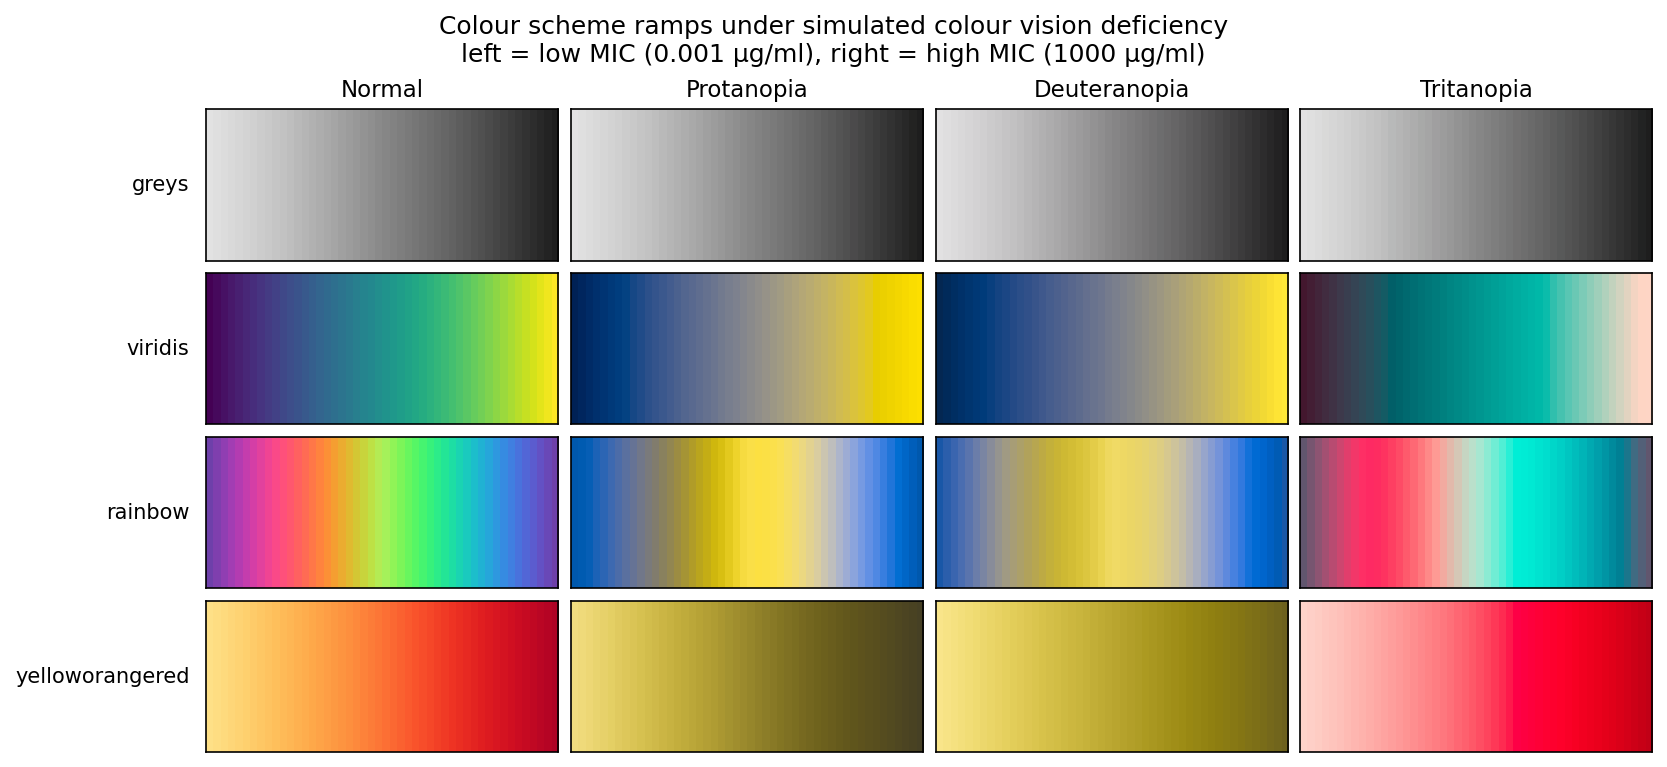

In [5]:
from IPython.display import Image
Image('colour_vision_check.png')

## Export

The assignment asks for a single stand-alone HTML file.

In [6]:
small_multiple.save('solution.html')
print('saved solution.html')

saved solution.html
